# Tissue and Shell Growth
I've already mostly done this analysis in [growth_treatments.ipynb](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/phenotype_data/growth/growth_treatments.ipynb) but it's a mess and doesn't really make sense - so I'm going to just have a straightforward analysis here that just shows plots and statisticlaa testing and leave it at that!

## 0. load libraries

In [2]:
library(tidyverse)
library(cowplot) # add plots together
library(grid)
library(RColorBrewer)

# for stat testing
library(lme4) # for linear mixed effects model
library(ggpubr)
library(car)
library(rstatix)
library(emmeans) #for post hocs
library(plotrix) #for standard error

set contrasts for statistical analysis

In [3]:
options(contrasts = c("contr.sum","contr.poly")) #could also be contr.treatment for unequal groups sum
getOption("contrasts") 

[1] "contr.sum"  "contr.poly"

## 1. read CSVs

#### metadata
to pull out sequenced oysters

In [4]:
meta <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/sample_metaData.csv')
head(meta)

,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1
2,B1_Nu_O03,both,warm,hypoxic,1,NA,NA,NA,NA
3,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5
4,B2_B5_O51,both,warm,hypoxic,2,both,warm,hypoxic,5
5,B2_C4_O40,both,warm,hypoxic,2,control,ambient,normoxic,4
6,B2_Nu_O12,both,warm,hypoxic,2,NA,NA,NA,NA


#### phase 1

In [5]:
p1.growth <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/growth_phase1_weights.csv') %>%
# consistent sample naming
mutate(Sample = paste0(substr(Phase_1_treat,1,1), Phase_1_rep, '_Nu_', Tag_color, sprintf("%02d", Tag_num))) %>%
# pull final mass columns and metadata
select(Sample, 'Phase1_treatment' = Phase_1_treat, 'Phase1_temp' = Phase_1_temp, 'Phase1_DO' = Phase_1_DO, 
       Actual_tissue_growth_mg, Actual_shell_growth_mg, Ratio_tissue_shell_mg)

# pull out only the sequenced oysters
p1.growth <- p1.growth[p1.growth$Sample %in% meta$Sample,]

# set contrasts
p1.growth$Phase1_treatment <- factor(p1.growth$Phase1_treatment, levels = c('Cont', 'Hyp', 'Warm', 'Both'))

colnames(p1.growth)
head(p1.growth)

[1] "Sample"                  "Phase1_treatment"       
[3] "Phase1_temp"             "Phase1_DO"              
[5] "Actual_tissue_growth_mg" "Actual_shell_growth_mg" 
[7] "Ratio_tissue_shell_mg"

,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Actual_tissue_growth_mg,Actual_shell_growth_mg,Ratio_tissue_shell_mg
,<chr>,<fct>,<chr>,<chr>,<dbl>,<dbl>,<chr>
3,B1_Nu_O03,Both,Warm,Hyp,27.91340,77.58660,0.359770888
10,B2_Nu_O12,Both,Warm,Hyp,80.37700,150.42300,0.534339828
23,B3_Nu_O24,Both,Warm,Hyp,89.72824,120.97176,0.741728813
31,B4_Nu_O32,Both,Warm,Hyp,105.36056,145.03944,0.726426964
35,B5_Nu_O36,Both,Warm,Hyp,25.22362,32.77638,0.769566987
46,B6_Nu_O47,Both,Warm,Hyp,-12.30496,117.80496,-0.104451969


#### phase 2

In [34]:
p2.growth <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/growth_phase2.1_weights.csv') %>%
# consistent sample naming
mutate(Sample = paste0(substr(Phase_1_treat,1,1), Phase_1_rep, '_', substr(Phase_2_treat,1,1), Phase_2_rep, '_', Tag_color, sprintf("%02d", Tag_num))) %>%
# pull final mass columns and metadata
select(Sample, 'Phase1_treatment' = Phase_1_treat, 'Phase1_temp' = Phase_1_temp, 'Phase1_DO' = Phase_1_DO, 
       'Phase2_treatment' = Phase_2_treat, 'Phase2_temp' = Phase_2.1_temp, 'Phase2_DO' = Phase_2.1_DO,
       Actual_tissue_growth_mg, Actual_shell_growth_mg, Ratio_tissue_shell_mg)

# pull out only the sequenced oysters
p2.growth <- p2.growth[p2.growth$Sample %in% meta$Sample,]

# set contrasts
p2.growth$Phase1_treatment <- factor(p2.growth$Phase1_treatment, levels = c('Cont', 'Hyp', 'Warm', 'Both'))
p2.growth$Phase2_treatment <- factor(p2.growth$Phase2_treatment, levels = c('Cont', 'Hyp', 'Warm', 'Both'))
p2.growth$Phase1_DO <- factor(p2.growth$Phase1_DO, levels = c('Norm', 'Hyp'))
p2.growth$Phase1_temp <- factor(p2.growth$Phase1_temp, levels = c('Ambient', 'Warm'))
p2.growth$Phase2_DO <- factor(p2.growth$Phase2_DO, levels = c('Norm', 'Hyp'))
p2.growth$Phase2_temp <- factor(p2.growth$Phase2_temp, levels = c('Ambient', 'Warm'))


colnames(p2.growth)
head(p2.growth)

[1] "Sample"                  "Phase1_treatment"       
 [3] "Phase1_temp"             "Phase1_DO"              
 [5] "Phase2_treatment"        "Phase2_temp"            
 [7] "Phase2_DO"               "Actual_tissue_growth_mg"
 [9] "Actual_shell_growth_mg"  "Ratio_tissue_shell_mg"

,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase2_treatment,Phase2_temp,Phase2_DO,Actual_tissue_growth_mg,Actual_shell_growth_mg,Ratio_tissue_shell_mg
,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<chr>
1,B1_B1_O01,Both,Warm,Hyp,Both,Warm,Hyp,120.72448,210.2755,0.574125224
46,B1_W5_O50,Both,Warm,Hyp,Warm,Warm,Norm,85.61170,315.8883,0.271018901
57,B2_B5_O51,Both,Warm,Hyp,Both,Warm,Hyp,44.47852,114.3215,0.389065292
68,B2_C4_O40,Both,Warm,Hyp,Cont,Ambient,Norm,55.10972,164.9903,0.33401798
103,B3_B4_O41,Both,Warm,Hyp,Both,Warm,Hyp,116.17500,197.9250,0.586964759
114,B3_C3_O30,Both,Warm,Hyp,Cont,Ambient,Norm,241.35336,316.0466,0.763663743


## 2. phase 1 growth

Sophie's findings from the larger dataset:
- oysters grew less tissue and shell in phase 2 hypoxia (regardless of temperature and prev. exposures?)
- oysters grew less relative tissue (tissue:shell) later in life if exposed to early life warming

### tissue

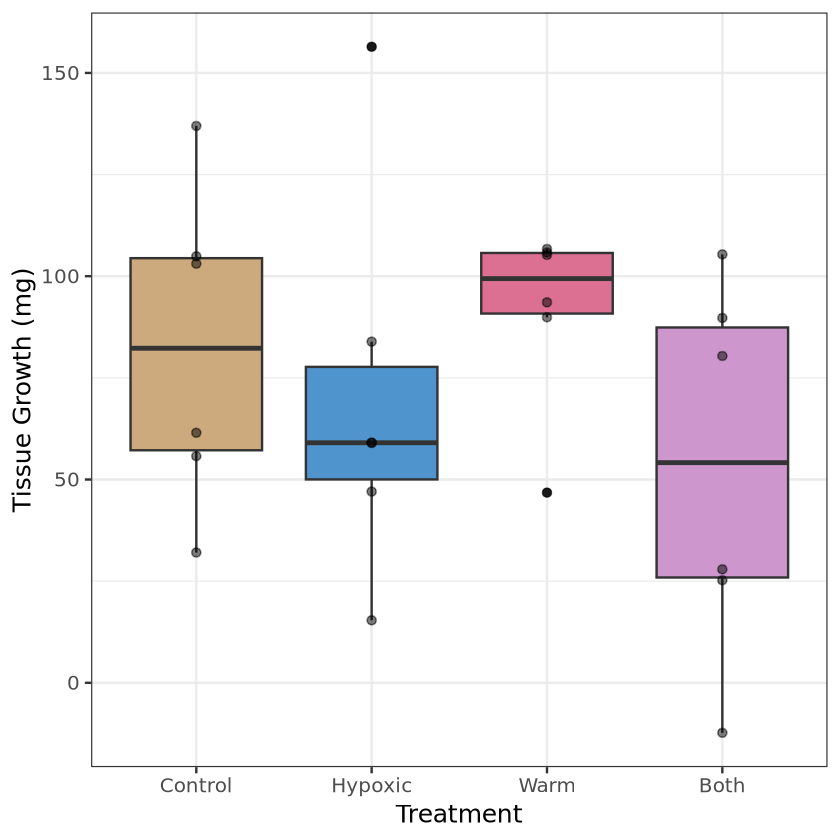

In [7]:
ggplot(p1.growth, aes(x = Phase1_treatment, y = Actual_tissue_growth_mg, fill = Phase1_treatment)) +
geom_boxplot() +
geom_point(alpha = 0.5) +
guides(fill = 'none') +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
labs(x = 'Treatment',
     y = 'Tissue Growth (mg)') +
theme_bw(base_size = 15)

oysters that experienced warming have higher average tissue growth than the other treatments (but there is a lot of overlap)

plotting how Sophie does (mean and SE):

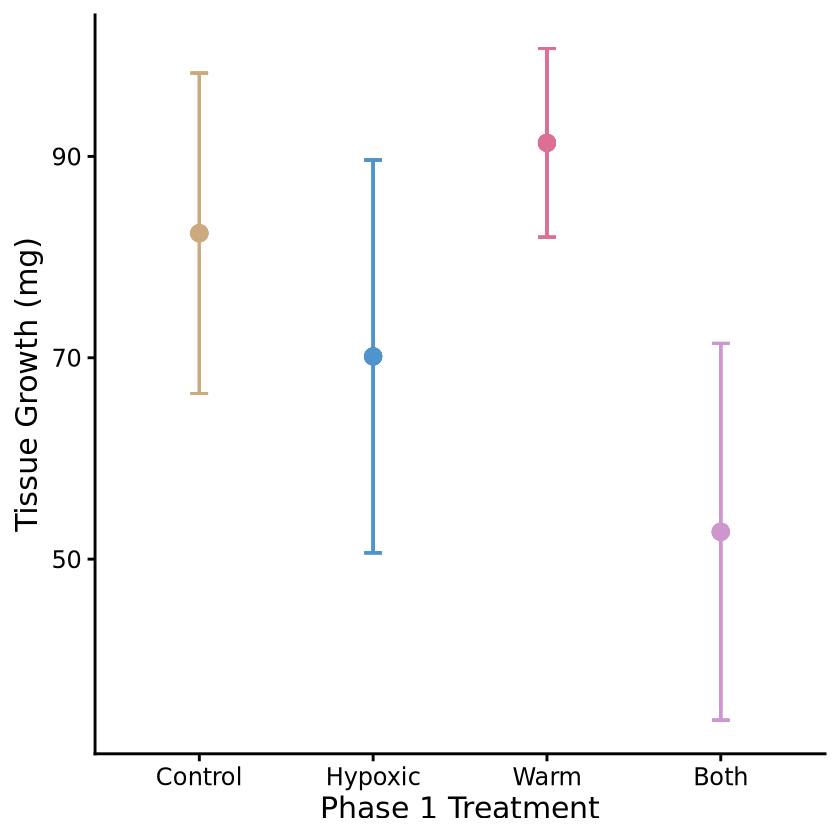

In [8]:
post_summary_stats_t <- p1.growth %>%
  group_by(Phase1_treatment) %>%
  mutate(
    mean_pre = mean(Actual_tissue_growth_mg, na.rm = TRUE),
    se_pre = std.error(Actual_tissue_growth_mg, na.rm = TRUE))

  #reorder effect of phase 1 Phase_1_treat
  post_summary_stats_t$Phase1_treatment <- factor(post_summary_stats_t$Phase1_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  
  #plot SHELL
  ggplot(post_summary_stats_t, aes(x = Phase1_treatment, y = mean_pre, color = Phase1_treatment)) +
    geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
    geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                  width = 0.1, position = position_dodge(0.9)) + # Error bars for SD
    theme_classic(base_size = 18)+
    scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    labs(x = "Phase 1 Treatment", y = "Tissue Growth (mg)") +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
   # ylim(330, 450)+
    theme(legend.position = "none") # Remove legend

#### stat testing:

In [9]:
m1 <- aov(Actual_tissue_growth_mg ~ Phase1_DO * Phase1_temp, data = p1.growth)
aov_tab <- Anova(m1, test="F", type="III")

summary(m1)

#remove scientific notation
aov_tab %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

                      Df Sum Sq Mean Sq F value Pr(>F)
Phase1_DO              1   3880    3880   2.414  0.136
Phase1_temp            1    107     107   0.067  0.799
Phase1_DO:Phase1_temp  1   1045    1045   0.650  0.430
Residuals             20  32149    1607               

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),131924.3483,1,82.07144175,0.0000
Phase1_DO,3880.1959,1,2.41390822,0.1359
Phase1_temp,106.9147,1,0.06651271,0.7991
Phase1_DO:Phase1_temp,1045.0103,1,0.65011121,0.4296
Residuals,32148.6611,20,NA,NA


no significant effect of treatments on growth

diagnostics

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,3,1.156307,0.350972
,20,NA,NA


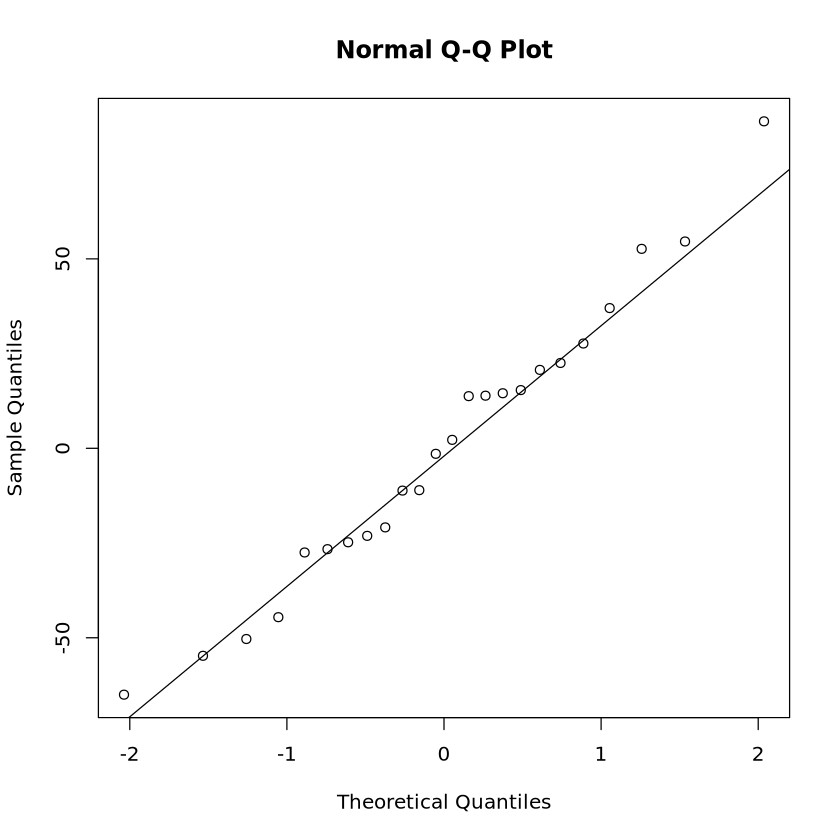

In [12]:
leveneTest((Actual_tissue_growth_mg) ~ Phase1_temp * Phase1_DO, p1.growth)
m1.e <- residuals(m1) 
qqnorm(m1.e)
qqline(m1.e)

passes levene test, no evidence of unequal variances

### shell

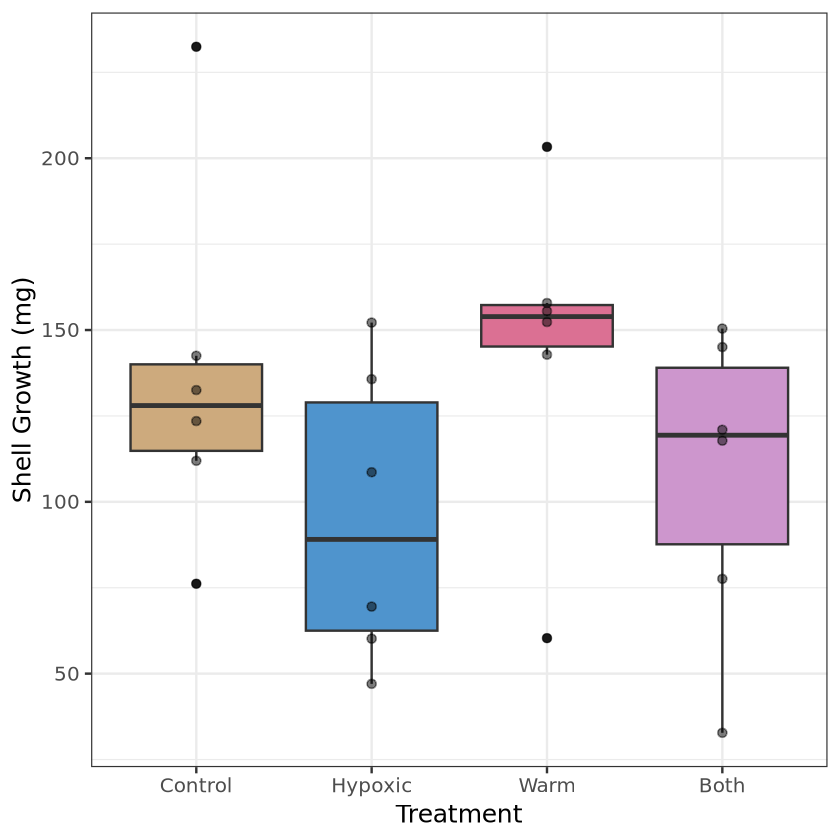

In [13]:
ggplot(p1.growth, aes(x = Phase1_treatment, y = Actual_shell_growth_mg, fill = Phase1_treatment)) +
geom_boxplot() +
geom_point(alpha = 0.5) +
guides(fill = 'none') +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
labs(x = 'Treatment',
     y = 'Shell Growth (mg)') +
theme_bw(base_size = 15)

oysters that experienced hypoxia (Hyp and Both) grew less on average than those that experienced normoxia (Cont and Warm) - also more variation in hyp and both treatments than control and warm treatments

plotting how Sophie does (mean and SE):

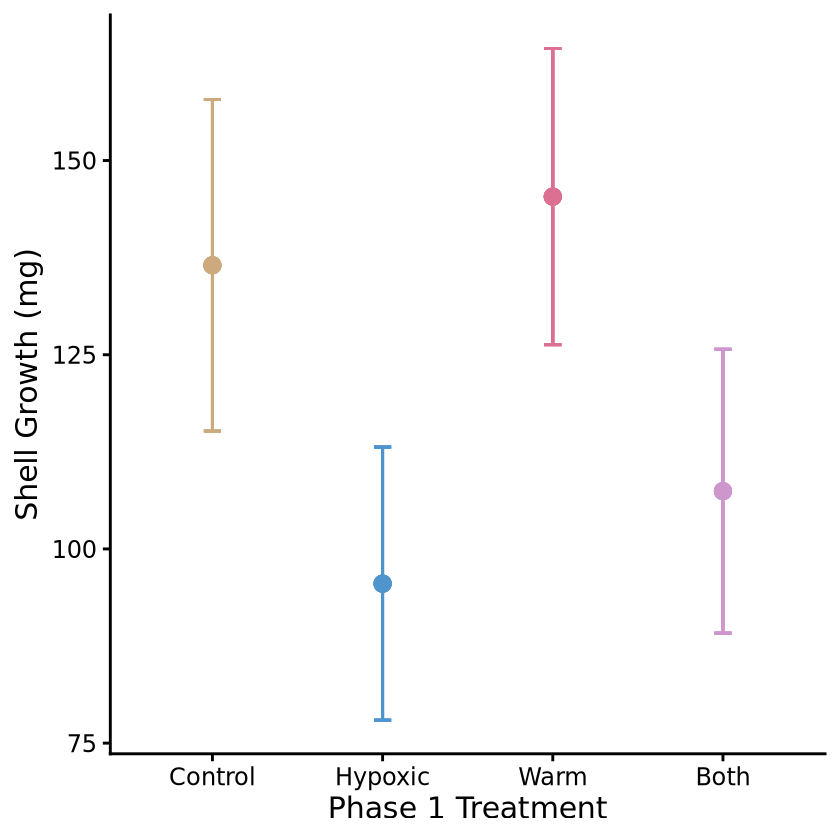

In [14]:
post_summary_stats_s <- p1.growth %>%
  group_by(Phase1_treatment) %>%
  mutate(
    mean_pre = mean(Actual_shell_growth_mg, na.rm = TRUE),
    se_pre = std.error(Actual_shell_growth_mg, na.rm = TRUE))

  #reorder effect of phase 1 Phase_1_treat
  post_summary_stats_s$Phase1_treatment <- factor(post_summary_stats_s$Phase1_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  
  #plot SHELL
  ggplot(post_summary_stats_s, aes(x = Phase1_treatment, y = mean_pre, color = Phase1_treatment)) +
    geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
    geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                  width = 0.1, position = position_dodge(0.9)) + # Error bars for SD
    theme_classic(base_size = 18)+
    scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    labs(x = "Phase 1 Treatment", y = "Shell Growth (mg)") +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
   # ylim(330, 450)+
    theme(legend.position = "none") # Remove legend

#### stat testing:

In [16]:
m2 <- aov(Actual_shell_growth_mg ~ Phase1_DO*Phase1_temp, data = p1.growth)
aov_tab2 <- Anova(m2, test="F", type="III")

summary(m2)

#remove scientific notation
aov_tab2 %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

                      Df Sum Sq Mean Sq F value Pr(>F)  
Phase1_DO              1   9339    9339   4.259 0.0523 .
Phase1_temp            1    645     645   0.294 0.5935  
Phase1_DO:Phase1_temp  1     14      14   0.006 0.9370  
Residuals             20  43862    2193                 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),352600.49121,1,1.607782e+02,0.0000
Phase1_DO,9339.25893,1,4.258500e+00,0.0523
Phase1_temp,645.37945,1,2.942791e-01,0.5935
Phase1_DO:Phase1_temp,14.05679,1,6.409591e-03,0.9370
Residuals,43861.72545,20,NA,NA


almost a significant effect of DO on shell growth (p = 0.0523)

diagnostics

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,3,0.09176316,0.9637265
,20,NA,NA


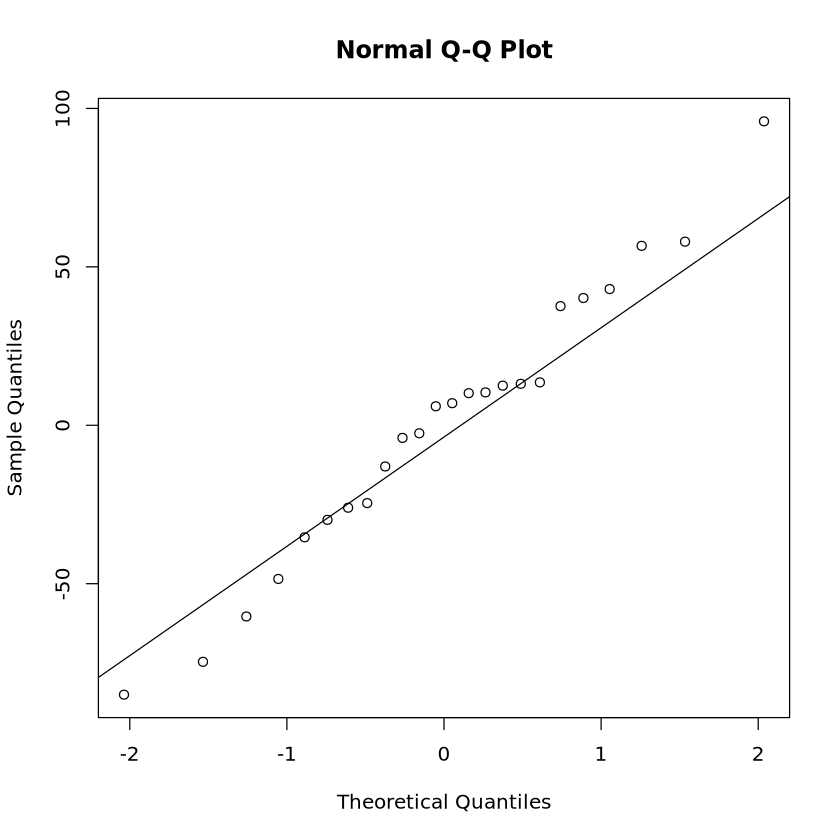

In [17]:
leveneTest((Actual_shell_growth_mg) ~ Phase1_temp * Phase1_DO, p1.growth)
m2.e <- residuals(m2) 
qqnorm(m2.e)
qqline(m2.e)

passes the levene test, no evidence of unequal variances

#### plot signif terms

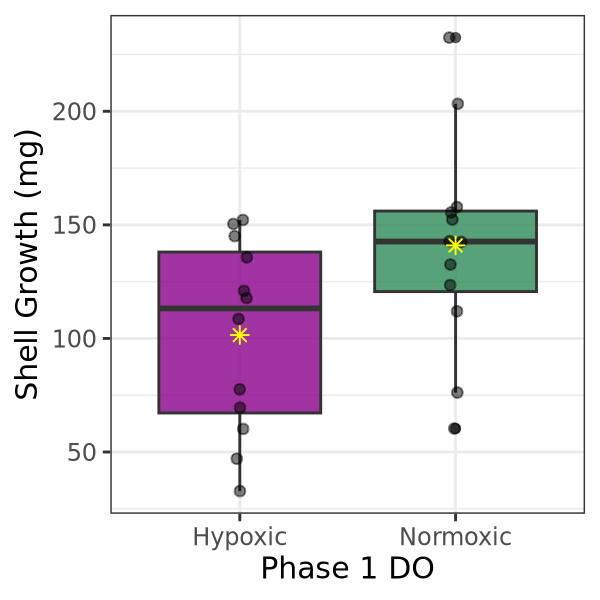

In [51]:
options(repr.plot.height = 5, repr.plot.width = 5)

ggplot(p1.growth, aes(x = Phase1_DO, y = Actual_shell_growth_mg, fill = Phase1_DO)) +
geom_boxplot(alpha = 0.8) +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
stat_summary(
    fun = "mean",
    geom = "point",
    shape = 8,
    size = 3,
    color = "yellow",
    position = position_dodge(width = 0.9)
  ) +
  scale_fill_manual(values = c("Hyp" = "darkmagenta", "Norm" = "seagreen")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Norm" = "Normoxic")) +
guides(fill = 'none') +
labs(x = 'Phase 1 DO',
     fill = 'Phase 1 DO',
     y = 'Shell Growth (mg)') +
theme_bw(base_size = 18)

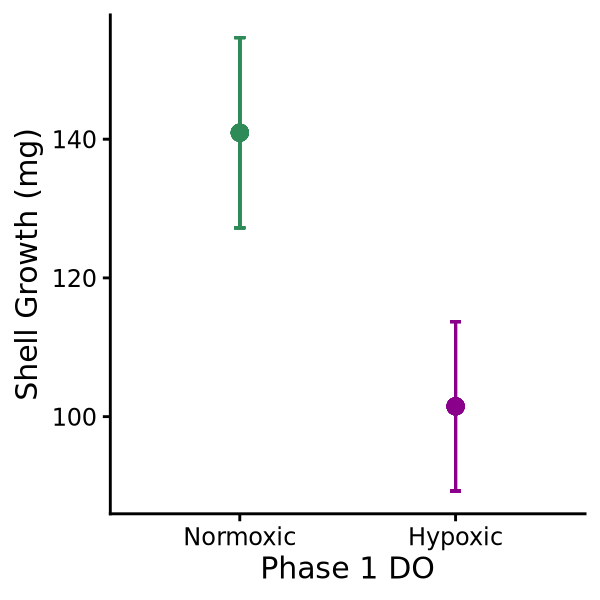

In [53]:
options(repr.plot.height = 5, repr.plot.width = 5)

pre_summary_stats_t <- p1.growth %>%
  group_by(Phase1_DO) %>%
  mutate(
    mean_pre = mean(Actual_shell_growth_mg, na.rm = TRUE),
    se_pre = std.error(Actual_shell_growth_mg, na.rm = TRUE))

#reorder
pre_summary_stats_t$Phase1_DO <- factor(pre_summary_stats_t$Phase1_DO, levels = c("Norm", "Hyp"))

#Tissue plot with mean and SD
ggplot(pre_summary_stats_t, aes(x = Phase1_DO, y = mean_pre, color = Phase1_DO)) +
  geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
  geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                width = 0.05, position = position_dodge(0.9)) + # Error bars for SD
  theme_classic(base_size = 18) +
  guides(color = "none") + # Remove legend for color
  scale_color_manual(values = c("Hyp" = "darkmagenta", "Norm" = "seagreen")) +
  scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Norm" = "Normoxic")) +
  labs(x = "Phase 1 DO", y = "Shell Growth (mg)") +
  theme(legend.position = "none") # Remove legend

### tissue:shell

In [20]:
p1.growth$Ratio_tissue_shell_mg <- as.numeric(p1.growth$Ratio_tissue_shell_mg)

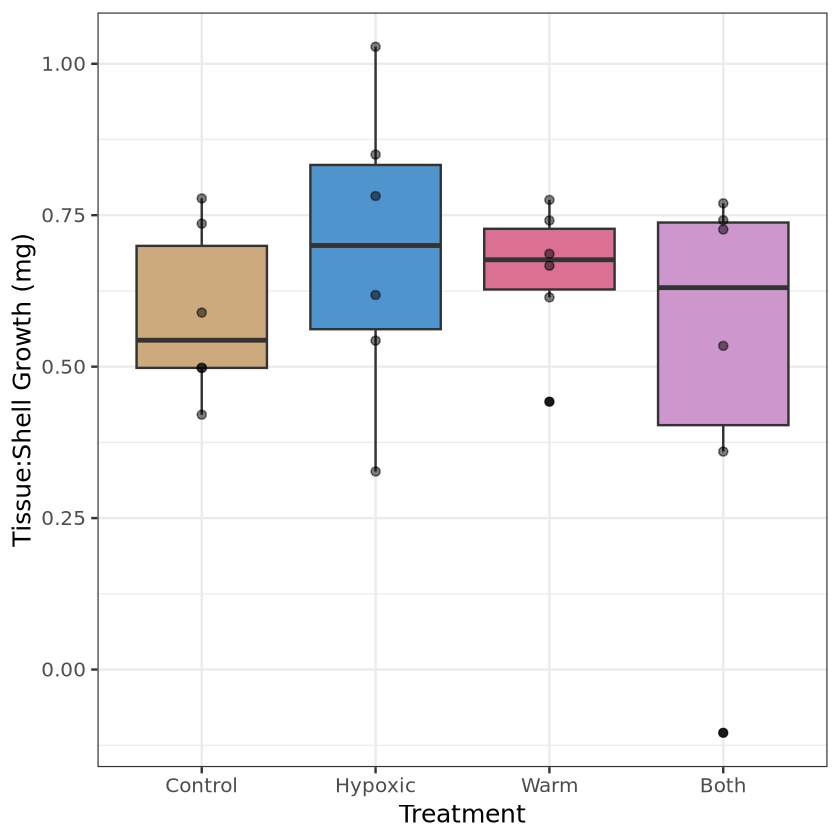

In [21]:
ggplot(p1.growth, aes(x = Phase1_treatment, y = Ratio_tissue_shell_mg, fill = Phase1_treatment)) +
geom_boxplot() +
geom_point(alpha = 0.5) +
guides(fill = 'none') +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
labs(x = 'Treatment',
     y = 'Tissue:Shell Growth (mg)') +
theme_bw(base_size = 15)

seems like maybe there's more variation in the both treatment - but **why is there a negative point?** it's really only possible to have negative tissue growth (like the oyster lost weight), if there was negative shell growth, that's likely due to chipping or dropping the shell during processing

In [25]:
range(p1.growth$Ratio_tissue_shell_mg)
range(p1.growth$Actual_shell_growth_mg)
range(p1.growth$Actual_tissue_growth_mg)

[1] -0.104452  1.028065

[1]  32.77638 232.44312

[1] -12.30496 156.43526

okay so yea we have one oyster (from both treatment) that had lost tissue during the exposure

plotting how Sophie does (mean and SE):

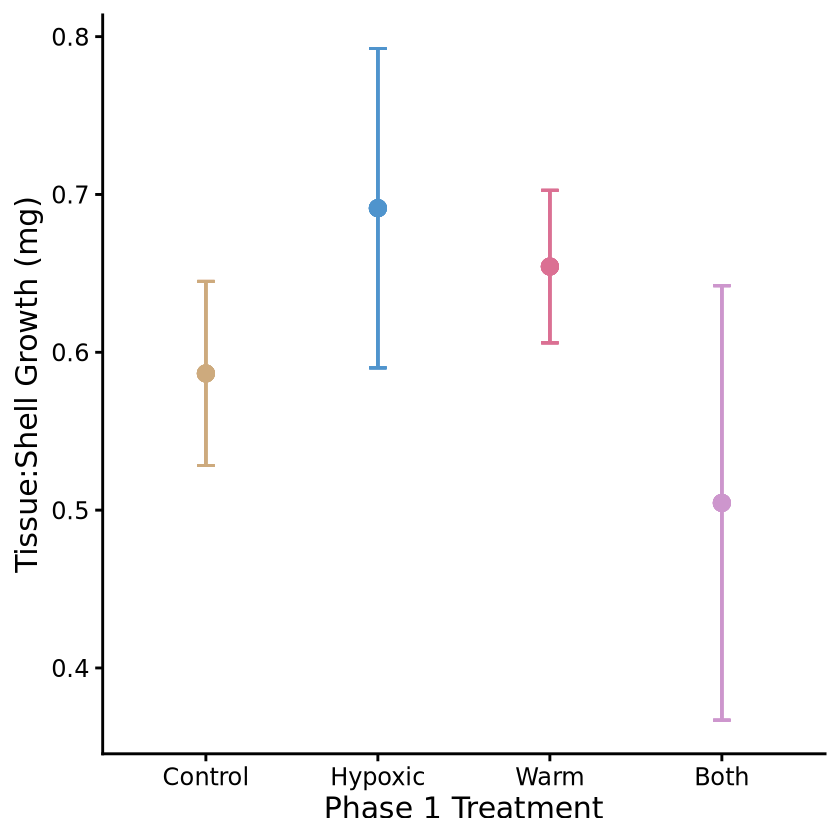

In [26]:
post_summary_stats_r <- p1.growth %>%
  group_by(Phase1_treatment) %>%
  mutate(
    mean_pre = mean(Ratio_tissue_shell_mg, na.rm = TRUE),
    se_pre = std.error(Ratio_tissue_shell_mg, na.rm = TRUE))

  #reorder effect of phase 1 Phase_1_treat
  post_summary_stats_r$Phase1_treatment <- factor(post_summary_stats_r$Phase1_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  
  #plot SHELL
  ggplot(post_summary_stats_r, aes(x = Phase1_treatment, y = mean_pre, color = Phase1_treatment)) +
    geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
    geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                  width = 0.1, position = position_dodge(0.9)) + # Error bars for SD
    theme_classic(base_size = 18)+
    scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    labs(x = "Phase 1 Treatment", y = "Tissue:Shell Growth (mg)") +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
   # ylim(330, 450)+
    theme(legend.position = "none") # Remove legend

#### stat testing:

In [27]:
m3 <- aov(Ratio_tissue_shell_mg ~ Phase1_DO*Phase1_temp, data = p1.growth)
aov_tab3 <- Anova(m3, test="F", type="III")

summary(m3)

#remove scientific notation
aov_tab3 %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

                      Df Sum Sq Mean Sq F value Pr(>F)
Phase1_DO              1 0.0030 0.00304   0.058  0.812
Phase1_temp            1 0.0213 0.02125   0.406  0.531
Phase1_DO:Phase1_temp  1 0.0972 0.09715   1.855  0.188
Residuals             20 1.0475 0.05237               

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),8.907141170,1,170.07254371,0.0000
Phase1_DO,0.003043416,1,0.05811085,0.8120
Phase1_temp,0.021250910,1,0.40576389,0.5314
Phase1_DO:Phase1_temp,0.097152318,1,1.85502188,0.1883
Residuals,1.047451984,20,NA,NA


no significant difference of tissue:shell growth (condition index) between treatments

diagnostics

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,3,1.414121,0.2680078
,20,NA,NA


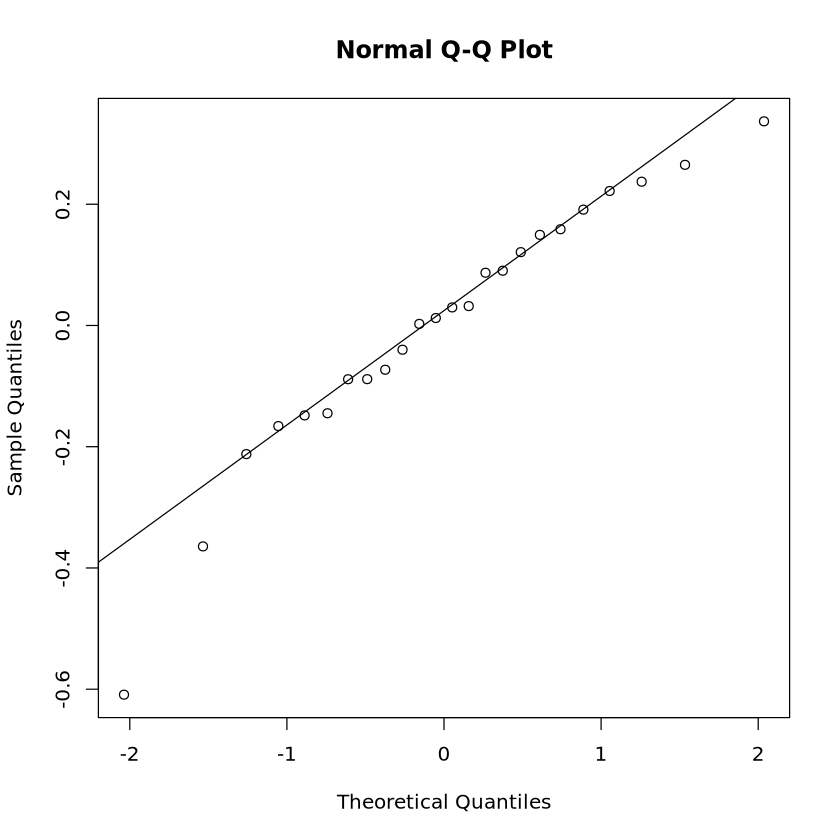

In [28]:
leveneTest((Ratio_tissue_shell_mg) ~ Phase1_temp * Phase1_DO, p1.growth)
m3.e <- residuals(m3) 
qqnorm(m3.e)
qqline(m3.e)

passes levene test, no evidence of unequal variances

## 3. phase 2 growth

### tissue

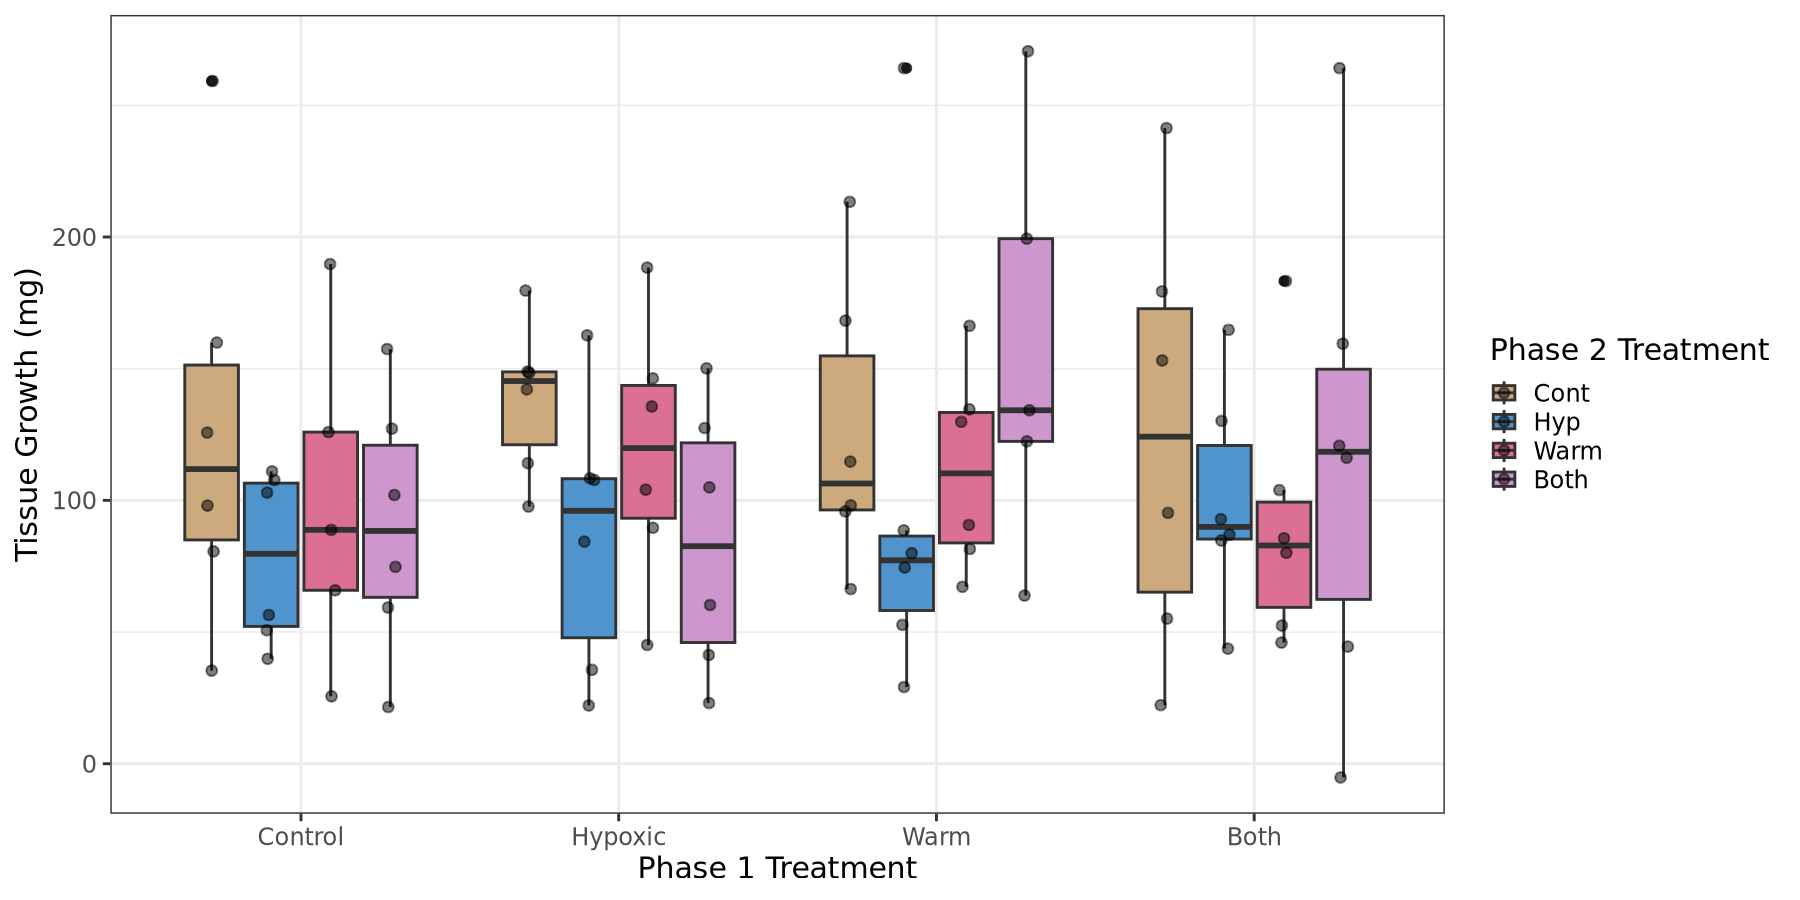

In [35]:
options(repr.plot.height = 7.5, repr.plot.width = 15)

ggplot(p2.growth, aes(x = Phase1_treatment, y = Actual_tissue_growth_mg, fill = Phase2_treatment)) +
geom_boxplot() +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
labs(x = 'Phase 1 Treatment',
     fill = 'Phase 2 Treatment',
     y = 'Tissue Growth (mg)') +
theme_bw(base_size = 18)

plotting how Sophie does (mean and SE):

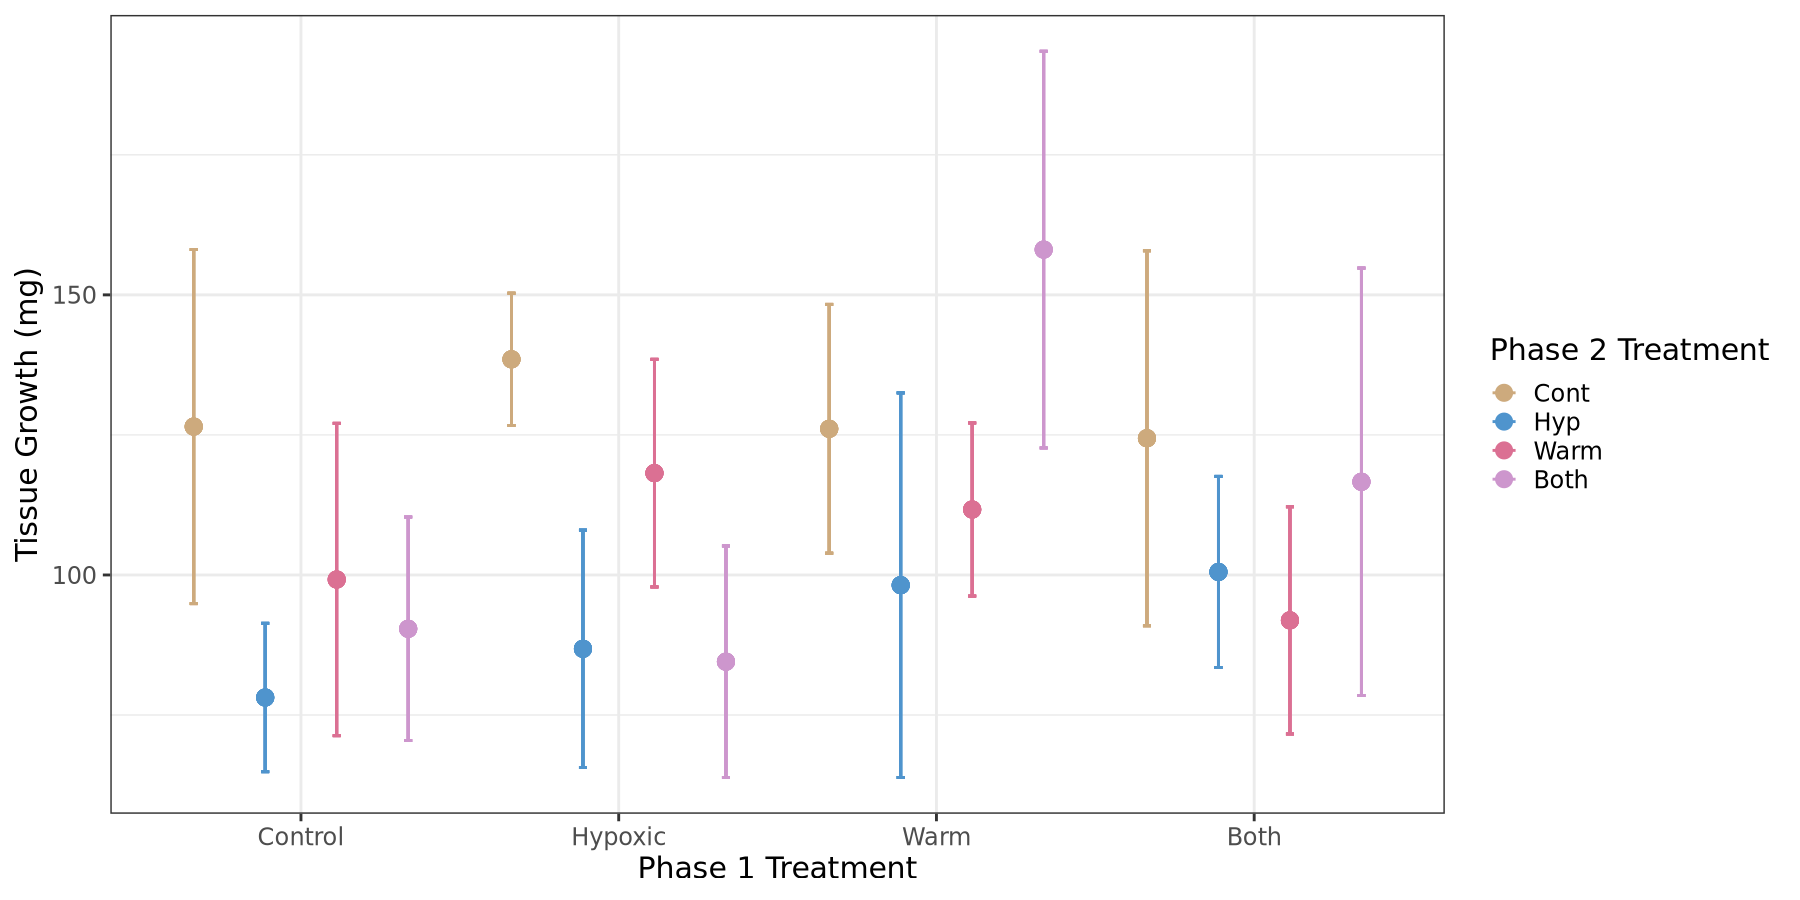

In [36]:
options(repr.plot.height = 7.5, repr.plot.width = 15)

post_summary_stats_t <- p2.growth %>%
  group_by(Phase1_treatment, Phase2_treatment) %>%
  mutate(
    mean_pre = mean(Actual_tissue_growth_mg, na.rm = TRUE),
    se_pre = std.error(Actual_tissue_growth_mg, na.rm = TRUE))

  #reorder effect of phase 1 Phase_1_treat
  post_summary_stats_t$Phase1_treatment <- factor(post_summary_stats_t$Phase1_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  post_summary_stats_t$Phase2_treatment <- factor(post_summary_stats_t$Phase2_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  
  #plot SHELL
  ggplot(post_summary_stats_t, aes(x = Phase1_treatment, y = mean_pre, color = Phase2_treatment)) +
    geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
    geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                  width = 0.1, position = position_dodge(0.9)) + # Error bars for SD
    theme_bw(base_size = 18)+
    scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    labs(x = "Phase 1 Treatment", 
         y = "Tissue Growth (mg)",
        color = 'Phase 2 Treatment') +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) 

yea looks like the standard error is so huge for these samples that there's no significant interactions/terms 


#### stat testing:

In [37]:
m4 <- aov(Actual_tissue_growth_mg ~ Phase1_DO * Phase1_temp * Phase2_DO * Phase2_temp, data = p2.growth)
aov_tab4 <- Anova(m4, test="F", type="III")

summary(m4)

#remove scientific notation
aov_tab4 %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

                                            Df Sum Sq Mean Sq F value Pr(>F)  
Phase1_DO                                    1    156     156   0.042 0.8373  
Phase1_temp                                  1   3492    3492   0.952 0.3323  
Phase2_DO                                    1   6568    6568   1.790 0.1849  
Phase2_temp                                  1     83      83   0.023 0.8810  
Phase1_DO:Phase1_temp                        1   2689    2689   0.733 0.3946  
Phase1_DO:Phase2_DO                          1    526     526   0.143 0.7061  
Phase1_temp:Phase2_DO                        1   9261    9261   2.524 0.1162  
Phase1_DO:Phase2_temp                        1   1701    1701   0.463 0.4981  
Phase1_temp:Phase2_temp                      1   1326    1326   0.361 0.5495  
Phase2_DO:Phase2_temp                        1  11614   11614   3.165 0.0791 .
Phase1_DO:Phase1_temp:Phase2_DO              1     55      55   0.015 0.9032  
Phase1_DO:Phase1_temp:Phase2_temp            1   103

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),1.120013e+06,1,3.052013e+02,0.0000
Phase1_DO,2.614289e+02,1,7.123887e-02,0.7902
Phase1_temp,4.056727e+03,1,1.105450e+00,0.2963
Phase2_DO,5.547657e+03,1,1.511726e+00,0.2226
Phase2_temp,2.685814e+01,1,7.318793e-03,0.9320
Phase1_DO:Phase1_temp,3.259485e+03,1,8.882034e-01,0.3489
Phase1_DO:Phase2_DO,7.671582e+02,1,2.090491e-01,0.6488
Phase1_temp:Phase2_DO,9.583167e+03,1,2.611395e+00,0.1101
Phase1_DO:Phase2_temp,1.766629e+03,1,4.814031e-01,0.4898


almost a significant interaction of phase 2 DO and temp on tissue growth (p = 0.0754) but not quite

diagnostics

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,15,0.6849976,0.7915304
,78,NA,NA


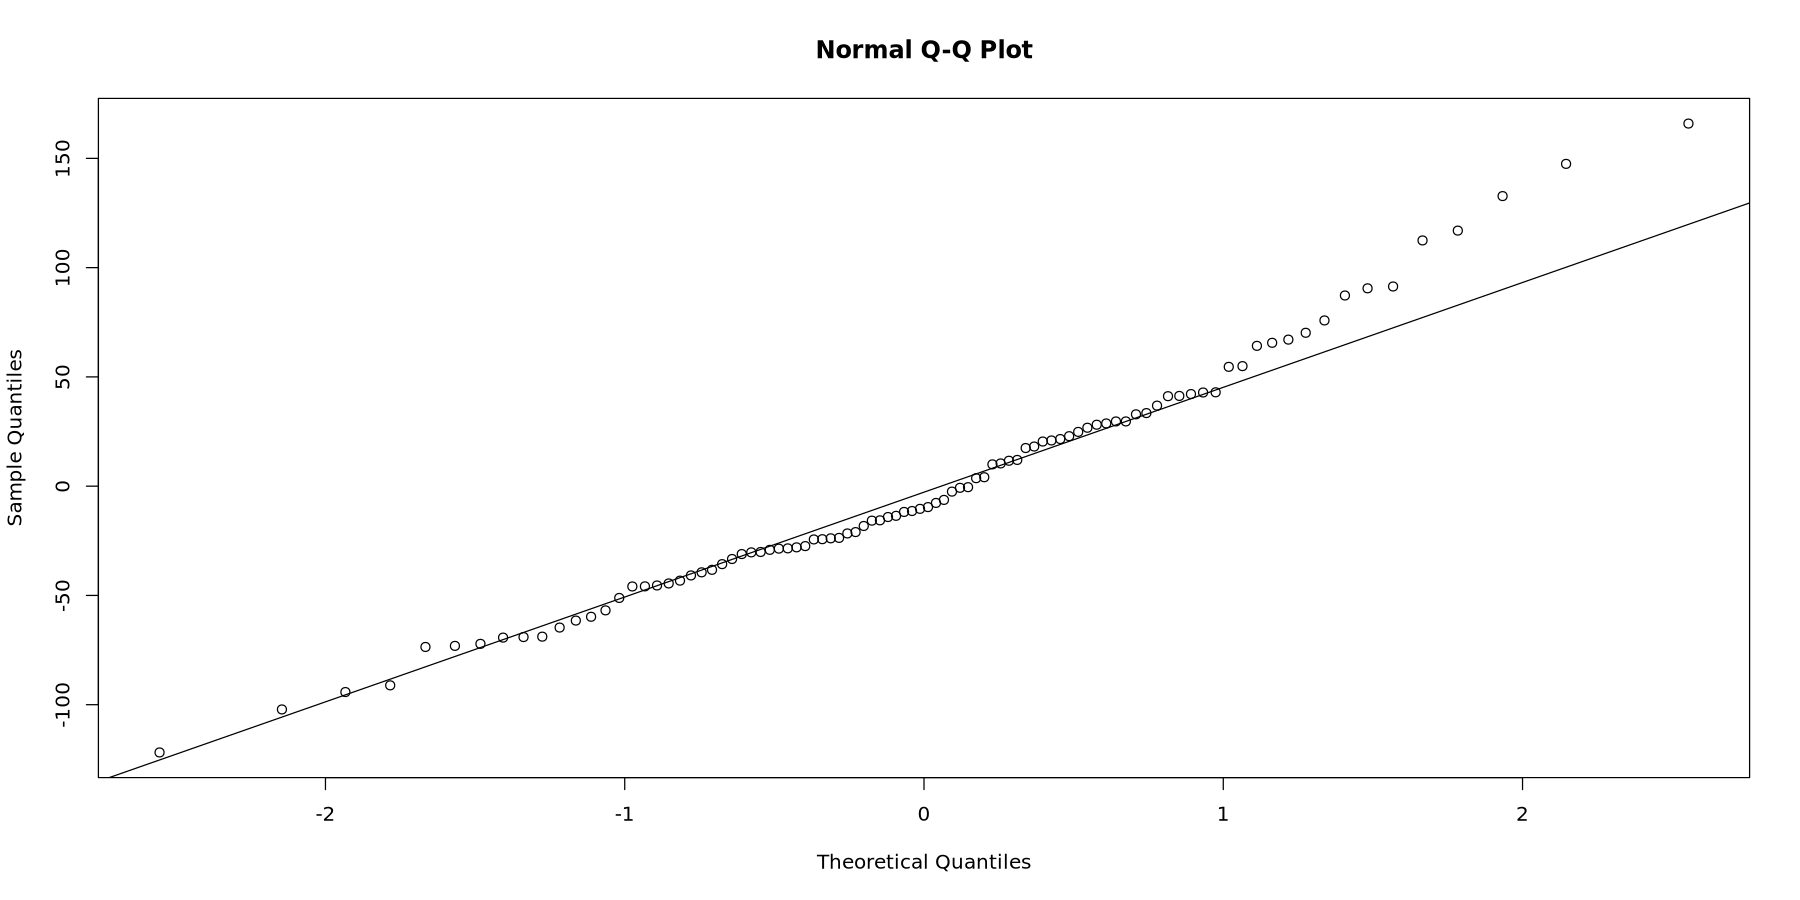

In [38]:
leveneTest((Actual_tissue_growth_mg) ~ Phase1_temp * Phase1_DO * Phase2_temp * Phase2_DO, p2.growth)
m4.e <- residuals(m4) 
qqnorm(m4.e)
qqline(m4.e)

passes levene test, no evidence of unequal variance

#### plot signif terms

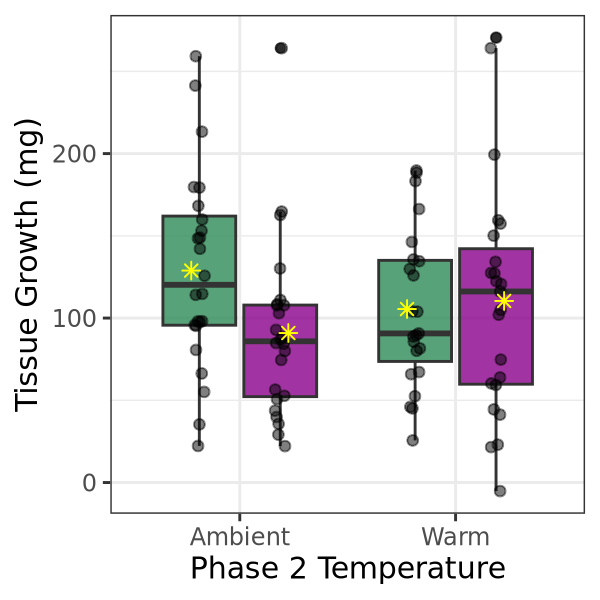

In [55]:
options(repr.plot.height = 5, repr.plot.width = 5)

ggplot(p2.growth, aes(x = Phase2_temp, y = Actual_tissue_growth_mg, fill = Phase2_DO)) +
geom_boxplot(alpha = 0.8) +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
stat_summary(
    fun = "mean",
    geom = "point",
    shape = 8,
    size = 3,
    color = "yellow",
    position = position_dodge(width = 0.9)
  ) +
  scale_fill_manual(values = c("Hyp" = "darkmagenta", "Norm" = "seagreen")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Norm" = "Normoxic")) +
guides(fill = 'none') +
labs(x = 'Phase 2 Temperature',
     fill = 'Phase 2 DO',
     y = 'Tissue Growth (mg)') +
theme_bw(base_size = 18)

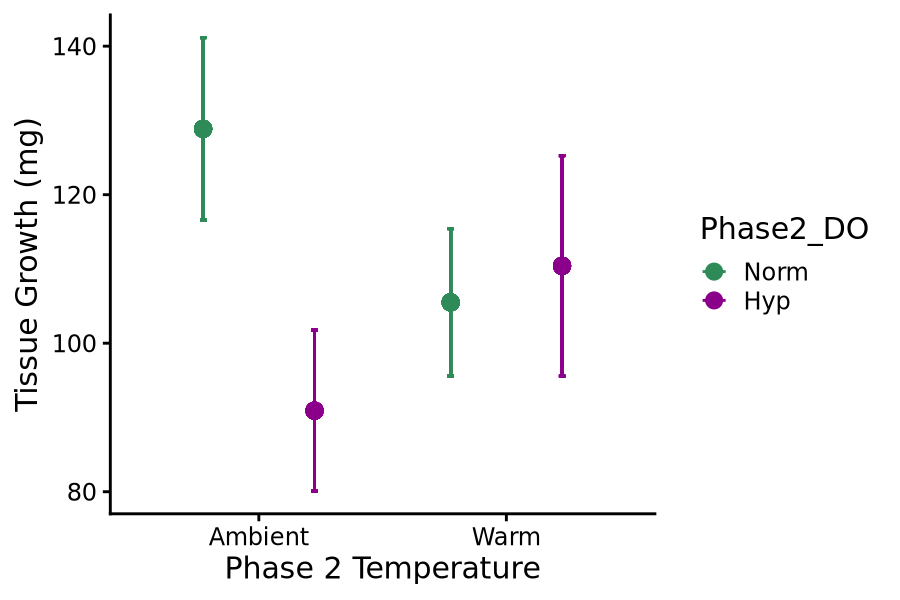

In [59]:
options(repr.plot.height = 5, repr.plot.width = 7.5)

pre_summary_stats_t <- p2.growth %>%
  group_by(Phase2_DO, Phase2_temp) %>%
  mutate(
    mean_pre = mean(Actual_tissue_growth_mg, na.rm = TRUE),
    se_pre = std.error(Actual_tissue_growth_mg, na.rm = TRUE))

#reorder
pre_summary_stats_t$Phase2_DO <- factor(pre_summary_stats_t$Phase2_DO, levels = c("Norm", "Hyp"))
pre_summary_stats_t$Phase2_temp <- factor(pre_summary_stats_t$Phase2_temp, levels = c("Ambient", "Warm"))


#Tissue plot with mean and SD
ggplot(pre_summary_stats_t, aes(x = Phase2_temp, y = mean_pre, color = Phase2_DO)) +
  geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
  geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                width = 0.05, position = position_dodge(0.9)) + # Error bars for SD
  theme_classic(base_size = 18) +
  #guides(color = "none") + # Remove legend for color
  scale_color_manual(values = c("Hyp" = "darkmagenta", "Norm" = "seagreen")) +
  #scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Norm" = "Normoxic")) +
  labs(x = "Phase 2 Temperature", y = "Tissue Growth (mg)")

ambient oysters grew less tissue in hypoxic conditions compared to normoxia (context-dependent effect?)

warm oysters grew about the same amount of tissue, regardless of the DO treatment

### shell

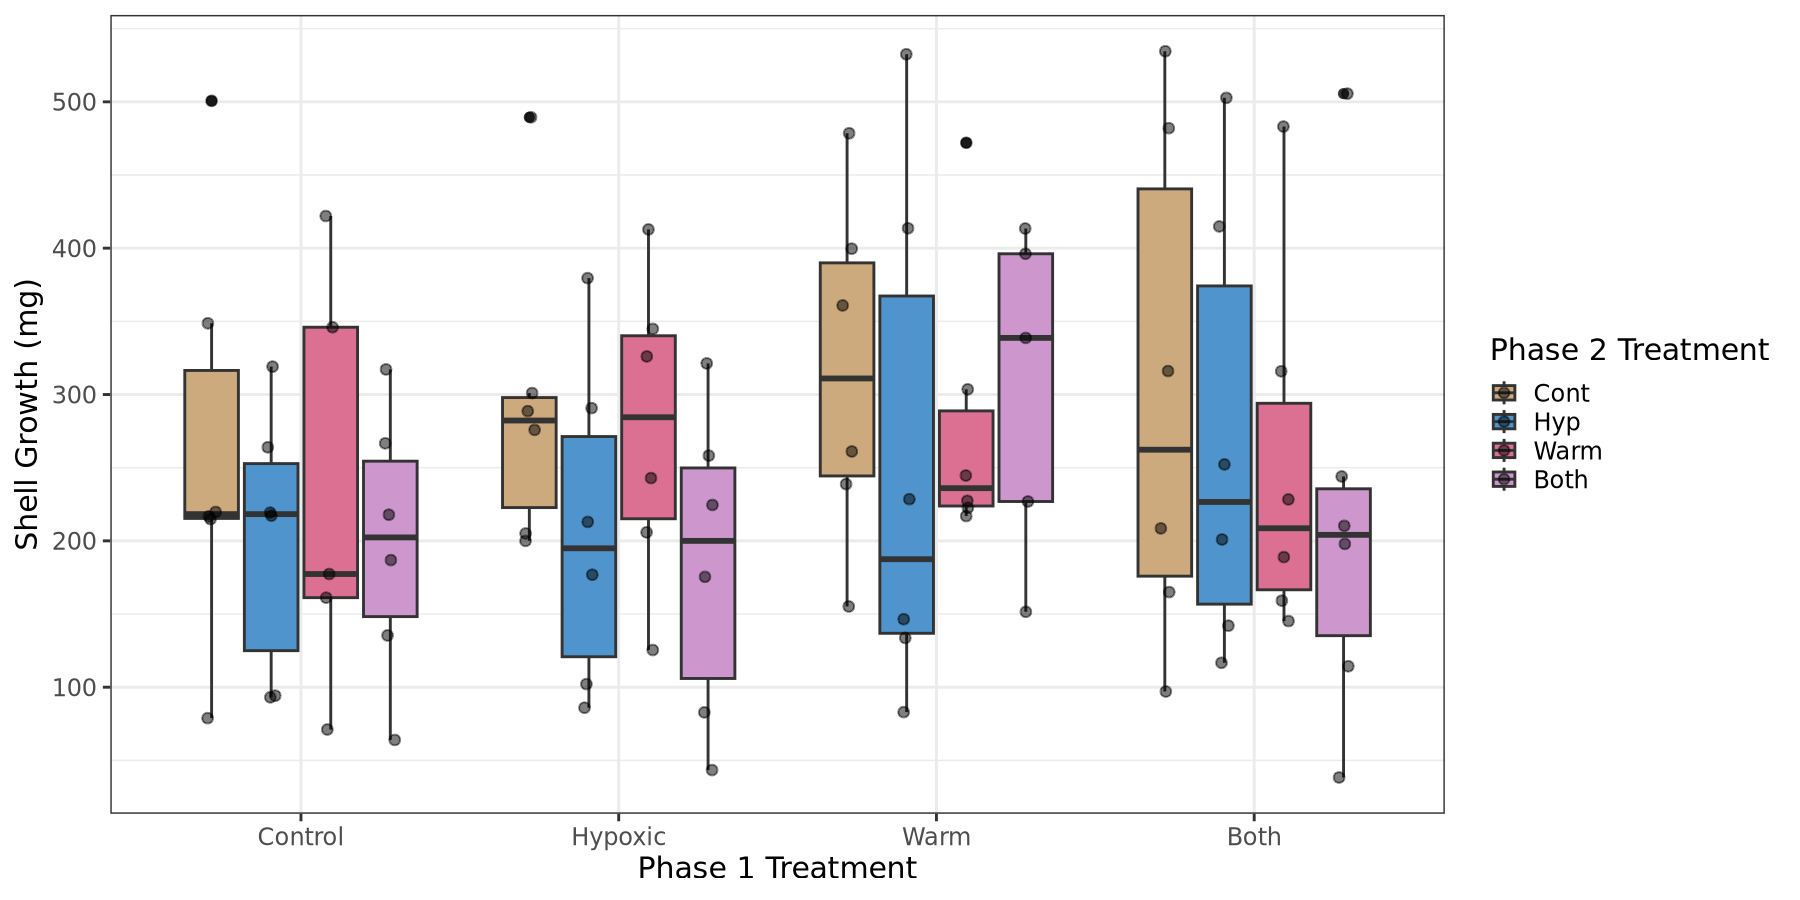

In [39]:
options(repr.plot.height = 7.5, repr.plot.width = 15)

ggplot(p2.growth, aes(x = Phase1_treatment, y = Actual_shell_growth_mg, fill = Phase2_treatment)) +
geom_boxplot() +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
labs(x = 'Phase 1 Treatment',
     fill = 'Phase 2 Treatment',
     y = 'Shell Growth (mg)') +
theme_bw(base_size = 18)

plotting how Sophie does (mean and SE):

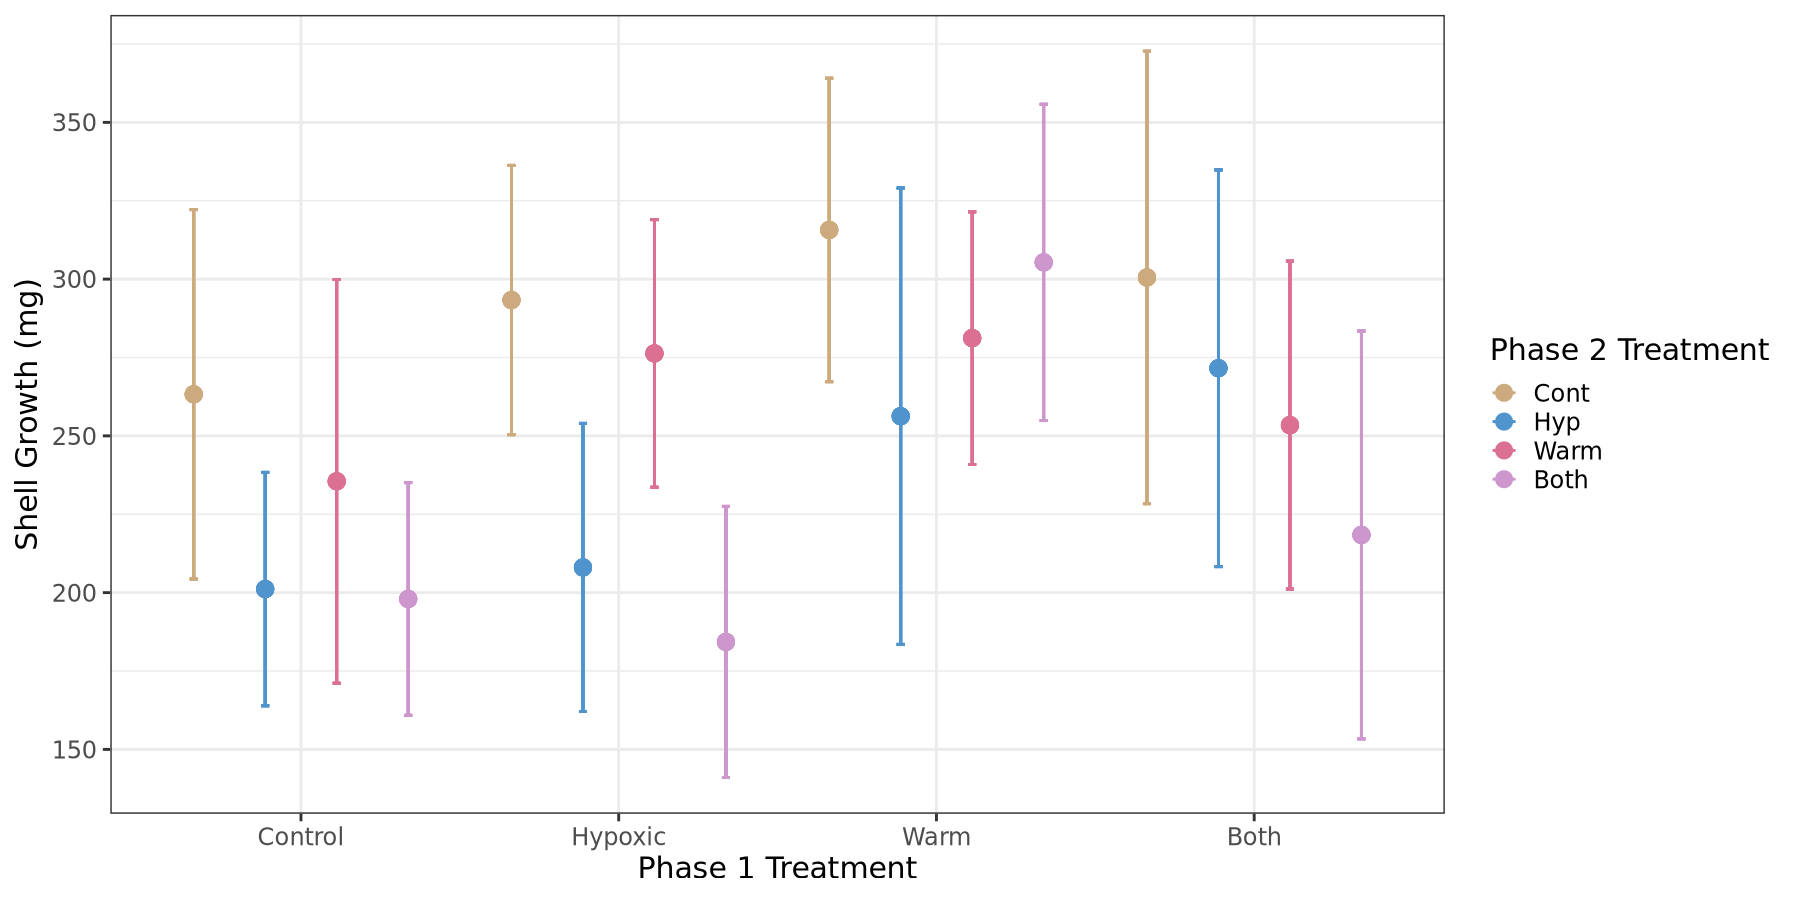

In [41]:
options(repr.plot.height = 7.5, repr.plot.width = 15)

post_summary_stats_s <- p2.growth %>%
  group_by(Phase1_treatment, Phase2_treatment) %>%
  mutate(
    mean_pre = mean(Actual_shell_growth_mg, na.rm = TRUE),
    se_pre = std.error(Actual_shell_growth_mg, na.rm = TRUE))

  #reorder effect of phase 1 Phase_1_treat
  post_summary_stats_s$Phase1_treatment <- factor(post_summary_stats_s$Phase1_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  post_summary_stats_s$Phase2_treatment <- factor(post_summary_stats_s$Phase2_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  
  #plot SHELL
  ggplot(post_summary_stats_s, aes(x = Phase1_treatment, y = mean_pre, color = Phase2_treatment)) +
    geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
    geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                  width = 0.1, position = position_dodge(0.9)) + # Error bars for SD
    theme_bw(base_size = 18)+
    scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    labs(x = "Phase 1 Treatment", 
         y = "Shell Growth (mg)", 
        color = 'Phase 2 Treatment') +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) 

oysters grew less shell when exposed to hypoxia twice (HH and HB)


#### stat testing:

In [42]:
m5 <- aov(Actual_shell_growth_mg ~ Phase1_DO * Phase1_temp * Phase2_DO * Phase2_temp, data = p2.growth)
aov_tab5 <- Anova(m5, test="F", type="III")

summary(m5)

#remove scientific notation
aov_tab5 %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

                                            Df  Sum Sq Mean Sq F value Pr(>F)  
Phase1_DO                                    1     772     772   0.046 0.8310  
Phase1_temp                                  1   41942   41942   2.491 0.1185  
Phase2_DO                                    1   55556   55556   3.300 0.0731 .
Phase2_temp                                  1   10066   10066   0.598 0.4417  
Phase1_DO:Phase1_temp                        1   10526   10526   0.625 0.4315  
Phase1_DO:Phase2_DO                          1    3622    3622   0.215 0.6440  
Phase1_temp:Phase2_DO                        1   11019   11019   0.654 0.4210  
Phase1_DO:Phase2_temp                        1    5554    5554   0.330 0.5674  
Phase1_temp:Phase2_temp                      1     169     169   0.010 0.9204  
Phase2_DO:Phase2_temp                        1    2965    2965   0.176 0.6759  
Phase1_DO:Phase1_temp:Phase2_DO              1     981     981   0.058 0.8099  
Phase1_DO:Phase1_temp:Phase2_temp       

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),6.037302e+06,1,3.585903e+02,0.0000
Phase1_DO,9.332098e+02,1,5.542873e-02,0.8145
Phase1_temp,4.293411e+04,1,2.550105e+00,0.1143
Phase2_DO,5.177506e+04,1,3.075220e+00,0.0834
Phase2_temp,9.063388e+03,1,5.383271e-01,0.4653
Phase1_DO:Phase1_temp,1.166752e+04,1,6.930015e-01,0.4077
Phase1_DO:Phase2_DO,4.140109e+03,1,2.459050e-01,0.6214
Phase1_temp:Phase2_DO,1.156018e+04,1,6.866259e-01,0.4098
Phase1_DO:Phase2_temp,5.690322e+03,1,3.379812e-01,0.5627


almost a significant effect of phase 2 DO on shell growth (p = 0.0834) but not quite

diagnostics

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,15,0.4775068,0.9452633
,78,NA,NA


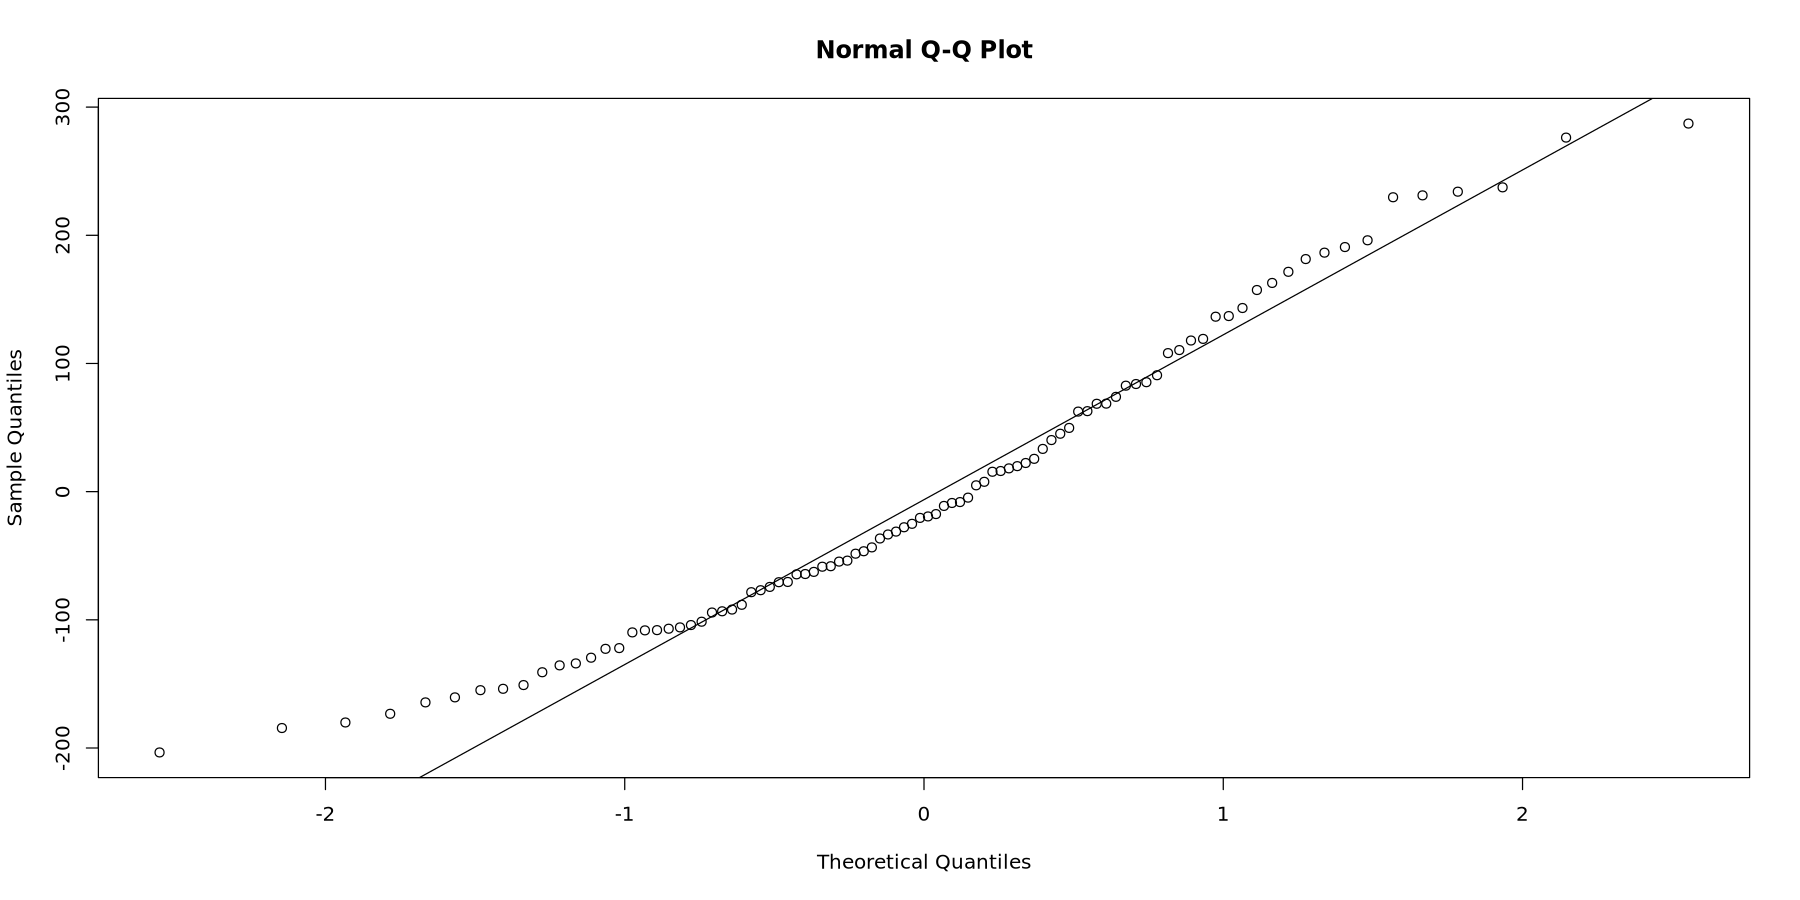

In [43]:
leveneTest((Actual_shell_growth_mg) ~ Phase1_temp * Phase1_DO * Phase2_temp * Phase2_DO, p2.growth)
m5.e <- residuals(m5) 
qqnorm(m5.e)
qqline(m5.e)

passes levene test, no evidence of unequal variances

#### plot signif terms

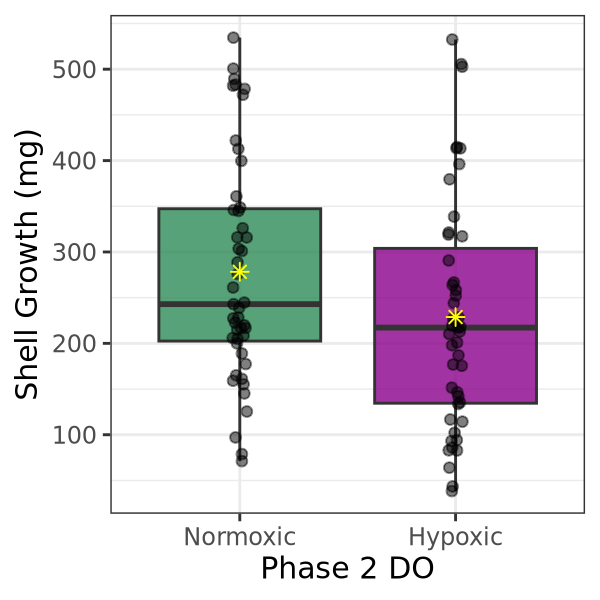

In [61]:
options(repr.plot.height = 5, repr.plot.width = 5)

ggplot(p2.growth, aes(x = Phase2_DO, y = Actual_shell_growth_mg, fill = Phase2_DO)) +
geom_boxplot(alpha = 0.8) +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
stat_summary(
    fun = "mean",
    geom = "point",
    shape = 8,
    size = 3,
    color = "yellow",
    position = position_dodge(width = 0.9)
  ) +
  scale_fill_manual(values = c("Hyp" = "darkmagenta", "Norm" = "seagreen")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Norm" = "Normoxic")) +
guides(fill = 'none') +
labs(x = 'Phase 2 DO',
     fill = 'Phase 2 DO',
     y = 'Shell Growth (mg)') +
theme_bw(base_size = 18)

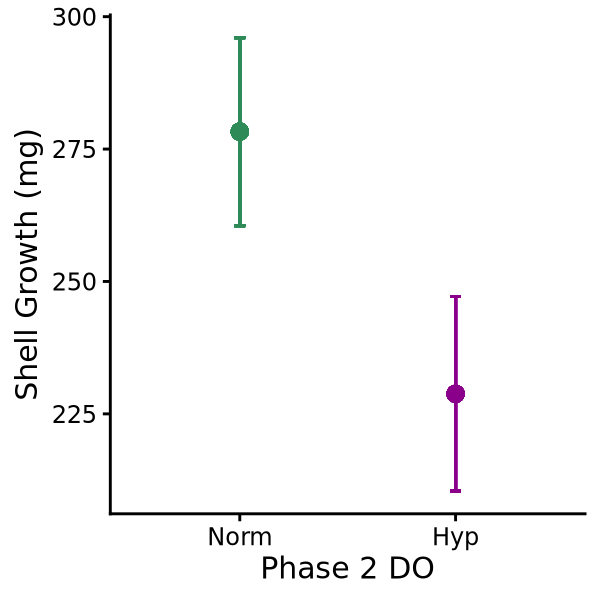

In [64]:
options(repr.plot.height = 5, repr.plot.width = 5)

pre_summary_stats_t <- p2.growth %>%
  group_by(Phase2_DO) %>%
  mutate(
    mean_pre = mean(Actual_shell_growth_mg, na.rm = TRUE),
    se_pre = std.error(Actual_shell_growth_mg, na.rm = TRUE))

#reorder
pre_summary_stats_t$Phase2_DO <- factor(pre_summary_stats_t$Phase2_DO, levels = c("Norm", "Hyp"))

#Tissue plot with mean and SD
ggplot(pre_summary_stats_t, aes(x = Phase2_DO, y = mean_pre, color = Phase2_DO)) +
  geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
  geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                width = 0.05, position = position_dodge(0.9)) + # Error bars for SD
  theme_classic(base_size = 18) +
  guides(color = "none") + # Remove legend for color
  scale_color_manual(values = c("Hyp" = "darkmagenta", "Norm" = "seagreen")) +
  #scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Norm" = "Normoxic")) +
  labs(x = "Phase 2 DO", y = "Shell Growth (mg)")

Oysters grew less shell in phase 2 hypoxia (regardless of temperature and early life exposure)

### tissue:shell

In [45]:
p2.growth$Ratio_tissue_shell_mg <- as.numeric(p2.growth$Ratio_tissue_shell_mg)

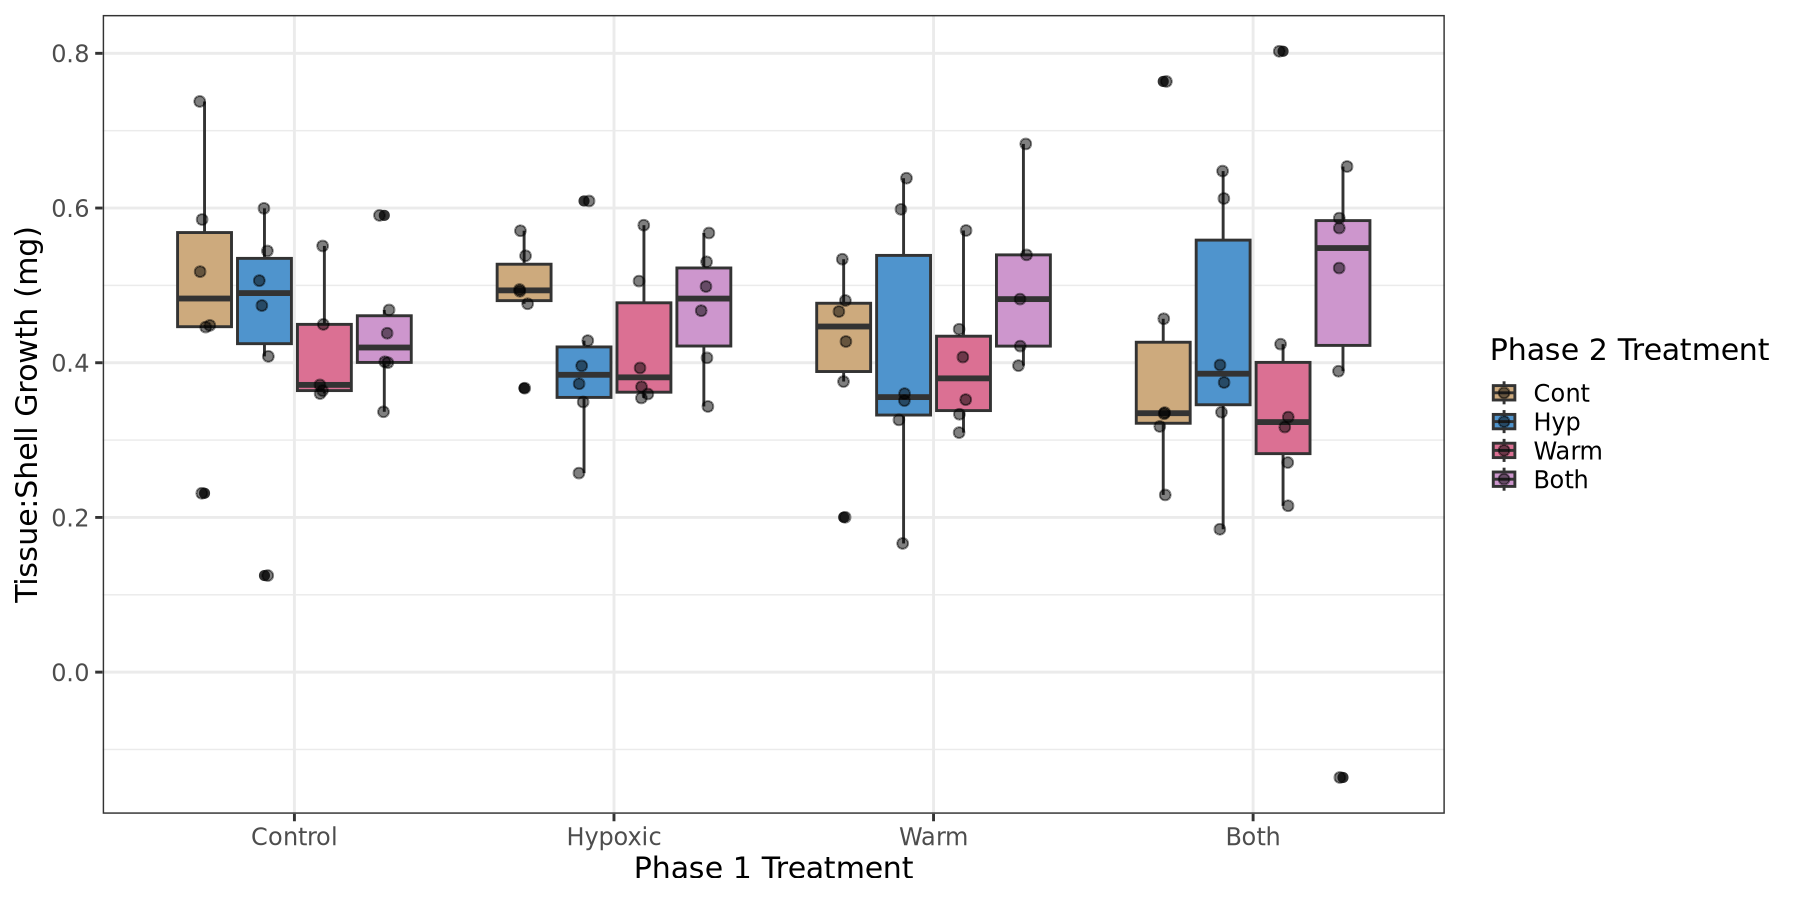

In [46]:
ggplot(p2.growth, aes(x = Phase1_treatment, y = Ratio_tissue_shell_mg, fill = Phase2_treatment)) +
geom_boxplot() +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
labs(x = 'Phase 1 Treatment',
     fill = 'Phase 2 Treatment',
     y = 'Tissue:Shell Growth (mg)') +
theme_bw(base_size = 18)

hmm okay looks like a lot of context-dependent patterns (treatments behave differently depending on the early life treatment)

plotting how Sophie does (mean and SE):

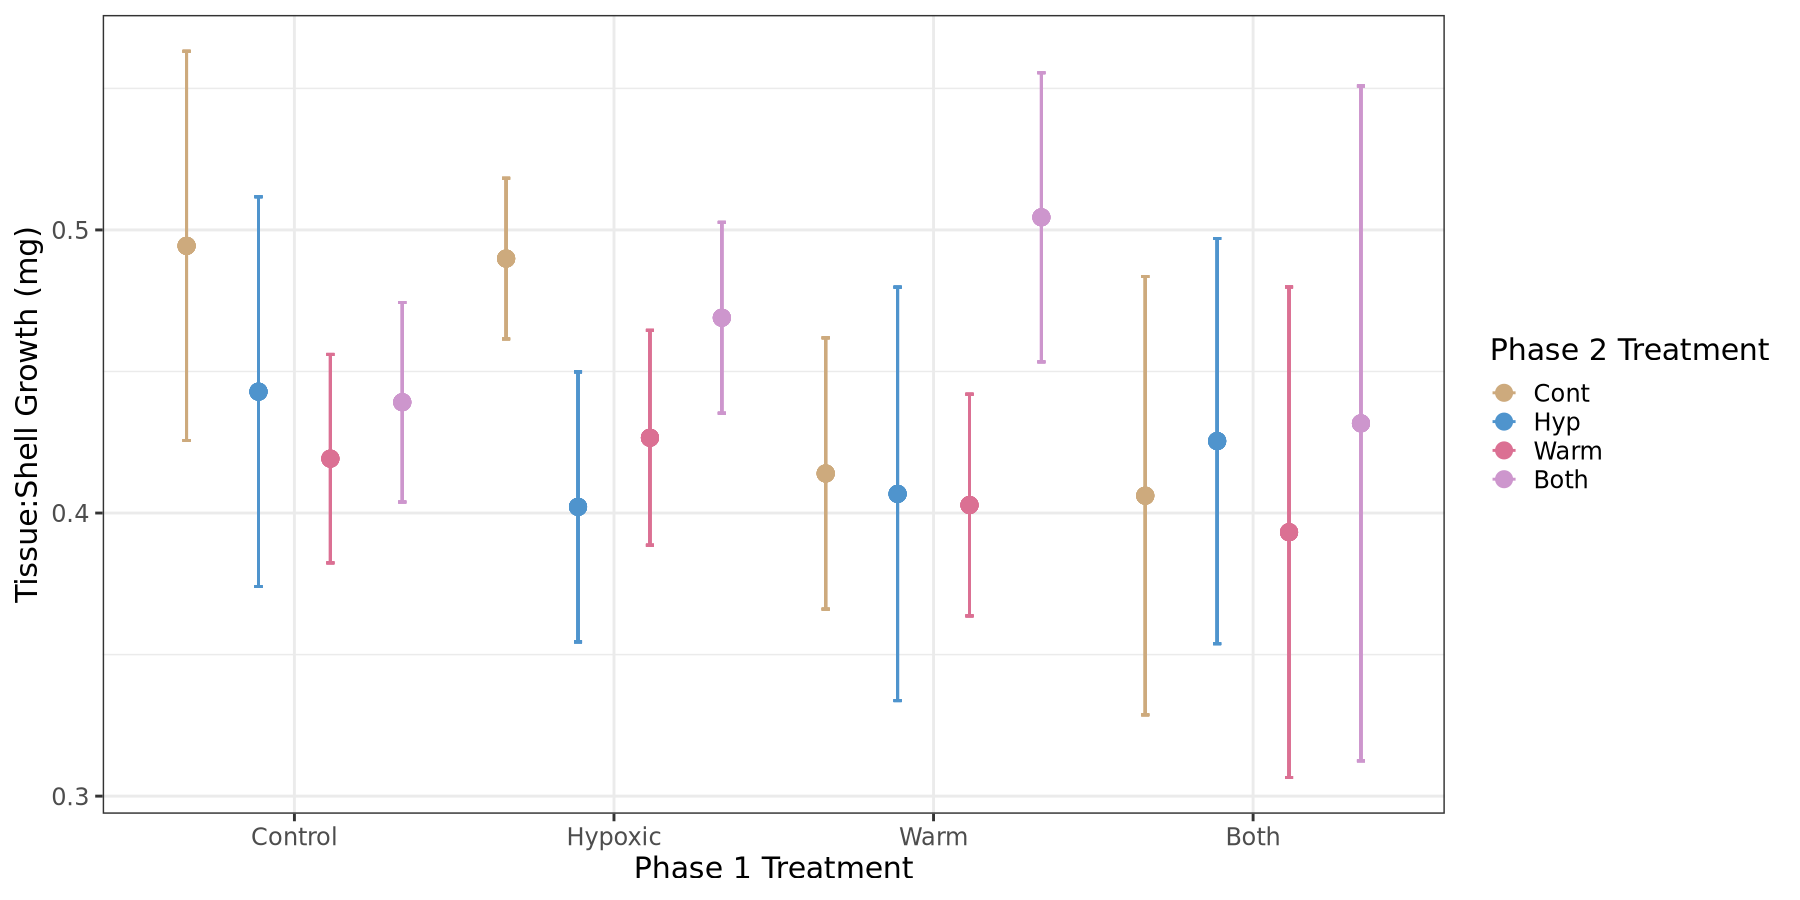

In [47]:
post_summary_stats_r <- p2.growth %>%
  group_by(Phase1_treatment, Phase2_treatment) %>%
  mutate(
    mean_pre = mean(Ratio_tissue_shell_mg, na.rm = TRUE),
    se_pre = std.error(Ratio_tissue_shell_mg, na.rm = TRUE))

  #reorder effect of phase 1 Phase_1_treat
  post_summary_stats_r$Phase1_treatment <- factor(post_summary_stats_r$Phase1_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  post_summary_stats_r$Phase2_treatment <- factor(post_summary_stats_r$Phase2_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  
  #plot RATIO
  ggplot(post_summary_stats_r, aes(x = Phase1_treatment, y = mean_pre, color = Phase2_treatment)) +
    geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
    geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                  width = 0.1, position = position_dodge(0.9)) + # Error bars for SD
    theme_bw(base_size = 18)+
    scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    labs(x = "Phase 1 Treatment", 
         y = "Tissue:Shell Growth (mg)",
        color = 'Phase 2 Treatment') +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) 

#### stat testing:

In [48]:
m6 <- aov(Ratio_tissue_shell_mg ~ Phase1_DO * Phase1_temp * Phase2_DO * Phase2_temp, data = p2.growth)
aov_tab6 <- Anova(m6, test="F", type="III")

summary(m6)

#remove scientific notation
aov_tab6 %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

                                            Df Sum Sq Mean Sq F value Pr(>F)
Phase1_DO                                    1 0.0019 0.00191   0.081  0.776
Phase1_temp                                  1 0.0174 0.01737   0.741  0.392
Phase2_DO                                    1 0.0012 0.00122   0.052  0.820
Phase2_temp                                  1 0.0000 0.00000   0.000  0.991
Phase1_DO:Phase1_temp                        1 0.0008 0.00081   0.035  0.853
Phase1_DO:Phase2_DO                          1 0.0004 0.00044   0.019  0.891
Phase1_temp:Phase2_DO                        1 0.0188 0.01883   0.803  0.373
Phase1_DO:Phase2_temp                        1 0.0000 0.00003   0.001  0.973
Phase1_temp:Phase2_temp                      1 0.0075 0.00747   0.319  0.574
Phase2_DO:Phase2_temp                        1 0.0386 0.03860   1.645  0.203
Phase1_DO:Phase1_temp:Phase2_DO              1 0.0002 0.00016   0.007  0.934
Phase1_DO:Phase1_temp:Phase2_temp            1 0.0112 0.01119   0.477  0.492

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),1.776210e+01,1,7.571790e+02,0.0000
Phase1_DO,2.314037e-03,1,9.864484e-02,0.7543
Phase1_temp,1.445520e-02,1,6.162095e-01,0.4348
Phase2_DO,2.073078e-03,1,8.837305e-02,0.7670
Phase2_temp,7.414001e-06,1,3.160507e-04,0.9859
Phase1_DO:Phase1_temp,1.480572e-03,1,6.311517e-02,0.8023
Phase1_DO:Phase2_DO,9.300623e-04,1,3.964754e-02,0.8427
Phase1_temp:Phase2_DO,1.919604e-02,1,8.183061e-01,0.3685
Phase1_DO:Phase2_temp,4.252140e-05,1,1.812641e-03,0.9661


no significant effect of treatment on condition index/relative tissue growth

diagnostics

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,15,0.5097496,0.9282251
,78,NA,NA


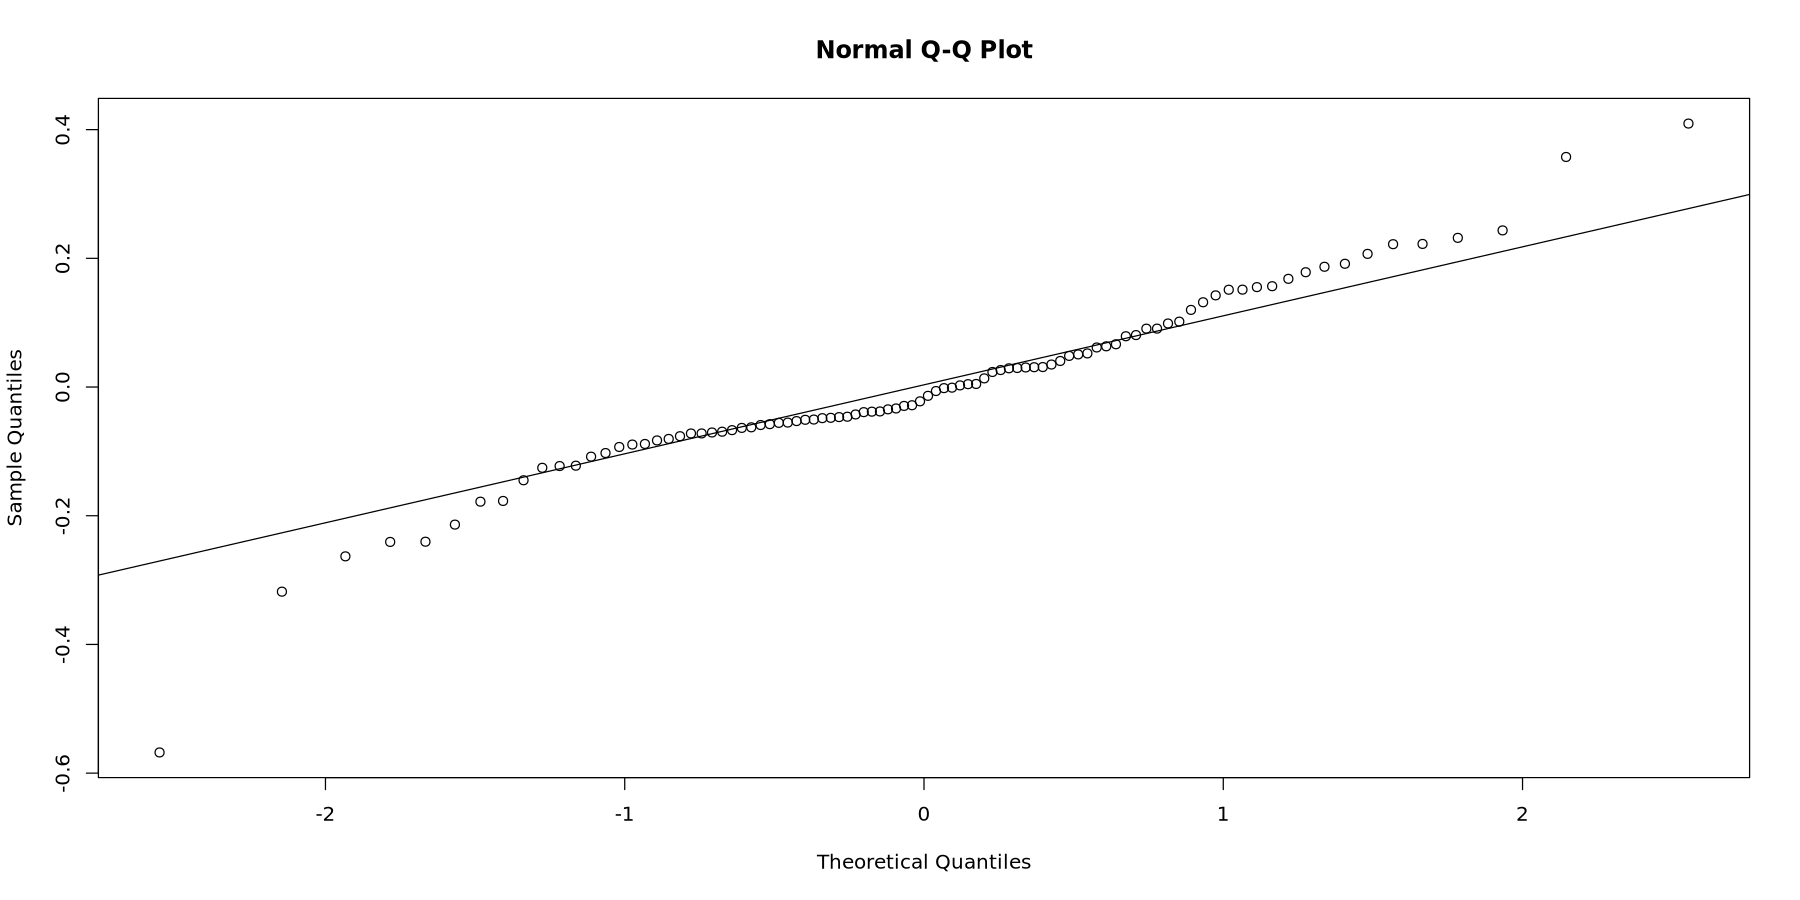

In [49]:
leveneTest((Ratio_tissue_shell_mg) ~ Phase1_temp * Phase1_DO * Phase2_temp * Phase2_DO, p2.growth)
m6.e <- residuals(m6) 
qqnorm(m6.e)
qqline(m6.e)

passes the levene test, no evidence of unequal variances

## 4. conclusions: